In [ ]:
# 환경 세팅

# 시스템 패키지 설치
system("apt-get update -qq")
system("apt-get install -y libxml2-dev libcurl4-openssl-dev libssl-dev build-essential")

# R 재설치 환경 정리
unlink("/usr/local/lib/R/site-library/00LOCK*", recursive = TRUE)

# BiocManager 설치
install.packages("BiocManager", repos="https://cloud.r-project.org")

# Dependency 설치
BiocManager::install("S4Vectors", ask=FALSE, update=FALSE)
BiocManager::install("IRanges", ask=FALSE, update=FALSE)
BiocManager::install("GenomeInfoDb", ask=FALSE, update=FALSE)
BiocManager::install("SummarizedExperiment", ask=FALSE, update=FALSE)

# DESeq2 설치
BiocManager::install("DESeq2", ask=FALSE, update=FALSE)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'BiocVersion', 'S4Vectors'

also installing the dependency ‘BiocGenerics’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'IRanges'

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04

In [ ]:
# 필요한 라이브러리 로드
BiocManager::install("limma", ask=FALSE, update=FALSE) # limma 패키지 설치
library(DESeq2)
library(limma)

# 1. 통합 CSV 파일 불러오기
# 행(Row)이 유전자(gene_id)이므로 row.names = 1로 지정합니다.
counts_matrix <- read.csv("tcga_cancer_normal_counts.csv", row.names = 1, check.names = FALSE)

# 2. 샘플 ID(열 이름)로부터 자동으로 Target과 Batch 추출하기
sample_ids <- colnames(counts_matrix)

# (1) 암/정상 구별 (Sample Type 코드 추출)
# TCGA ID에서 4번째 세트(예: 01A, 11A)의 숫자 두 자리를 가져옵니다.
sample_types <- sapply(strsplit(sample_ids, "-"), `[`, 4)
sample_type_num <- substr(sample_types, 1, 2)

# 01~09는 Cancer, 11은 Normal로 분류
target <- ifelse(as.numeric(sample_type_num) < 10, "cancer", "normal")

# (2) 배치(Batch) 구별 (Plate ID 추출)
# TCGA ID에서 6번째 세트(예: 1755, A40A 등 바로 앞의 플레이트 바코드 세트)를 배치로 사용합니다.
# 안전하게 5번째 세트(Plate/Center 영역 전체)를 가져오기 위해 5번째 마디를 추출합니다.
batches <- sapply(strsplit(sample_ids, "-"), `[`, 5)

# 3. 메타데이터 데이터프레임 생성
metadata <- data.frame(
  row.names = sample_ids,
  target = as.factor(target),
  batch = as.factor(batches)
)

# DESeq2는 정수형 matrix를 원하므로 형변환
counts_matrix <- as.matrix(counts_matrix)
class(counts_matrix) <- "integer"

print("--- 샘플 정보 자동 추출 완료 ---")
print(table(metadata$target)) # 암/정상 샘플 수 확인

# 4. DESeq2 객체 생성 및 디자인 설정
dds <- DESeqDataSetFromMatrix(countData = counts_matrix,
                              colData = metadata,
                              design = ~ batch + target)

# 5. 정규화 (VST) 및 Batch Effect 제거
vsd <- vst(dds, blind = FALSE)
mat_vst <- assay(vsd)

# 분석 목적 변수인 target(암/정상)은 보존하고 batch만 제거
design <- model.matrix(~ target, data = metadata)
mat_corrected <- removeBatchEffect(mat_vst, batch = metadata$batch, design = design)

# 6. Python XGBoost가 먹기 좋은 형태로 변환 후 저장 [행=샘플, 열=유전자]
final_df <- as.data.frame(t(mat_corrected))
final_df$target <- ifelse(metadata$target == "cancer", 1, 0) # cancer=1, normal=0 변경
final_df$batch <- metadata$batch

# 전처리 완료된 파일 저장
write.csv(final_df, "corrected_data_for_xgboost.csv", row.names = TRUE)
print("R 단계 완료: TCGA ID 파싱 및 배치 제거 성공!")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'limma'

also installing the dependency ‘statmod’



Attaching package: ‘limma’


The following object is masked from ‘package:DESeq2’:

    plotMA


The following object is masked from ‘package:BiocGenerics’:

    plotMA




[1] "--- 샘플 정보 자동 추출 완료 ---"

cancer normal 
    93     16 
[1] "R 단계 완료: TCGA ID 파싱 및 배치 제거 성공!"


In [ ]:
# 데이터 준비 (Metadata 생성)

# 1. 카운트 데이터 불러오기
counts <- read.csv("tcga_lung_cancer_counts.csv", row.names=1)

# 2. 샘플 개수
num_samples <- ncol(counts)

# 3. 메타데이터 생성 (초기 틀)
sample_info <- data.frame(
  row.names = colnames(counts),
  condition = NA,   # 일단 비워두는 게 더 깔끔
  batch = rep(c("Batch1", "Batch2"), length.out = num_samples)
)

# 4. condition을 실제 TCGA 정보로 채우기
sample_info$condition <- ifelse(
  substr(colnames(counts), 14, 15) == "01",
  "Tumor",
  "Normal"
)

# 5. factor 변환
sample_info$condition <- factor(sample_info$condition)
sample_info$batch <- factor(sample_info$batch)

In [ ]:
# DESeq2 모델링 - batch effect 포함

# BiocManager가 설치되어 있지 않다면 먼저 설치합니다.
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

# DESeq2 패키지를 설치합니다.
BiocManager::install("DESeq2")

library(DESeq2)

# design 수식: ~ condition
# 앞서 임의로 만들었던 batch를 수식에서 제외함
dds <- DESeqDataSetFromMatrix(countData = counts,
                              colData = sample_info,
                              design = ~ condition)

# 분석 실행
dds <- DESeq(dds)

# 결과 추출 (배치 효과가 제어된 condition 간의 차이)
res <- results(dds, contrast=c("condition", "Tumor", "Normal"))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'BiocVersion', 'DESeq2'

also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘SummarizedExperiment’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’


Old packages: 'gh', 'xfun', 'xtable'

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘p

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'limma'

also installing the dependency ‘statmod’


Old packages: 'gh', 'xfun', 'xtable'


Attaching package: ‘limma’


The following object is masked from ‘package:DESeq2’:

    plotMA


The following object is masked from ‘package:BiocGenerics’:

    plotMA


using ntop=500 top features by variance



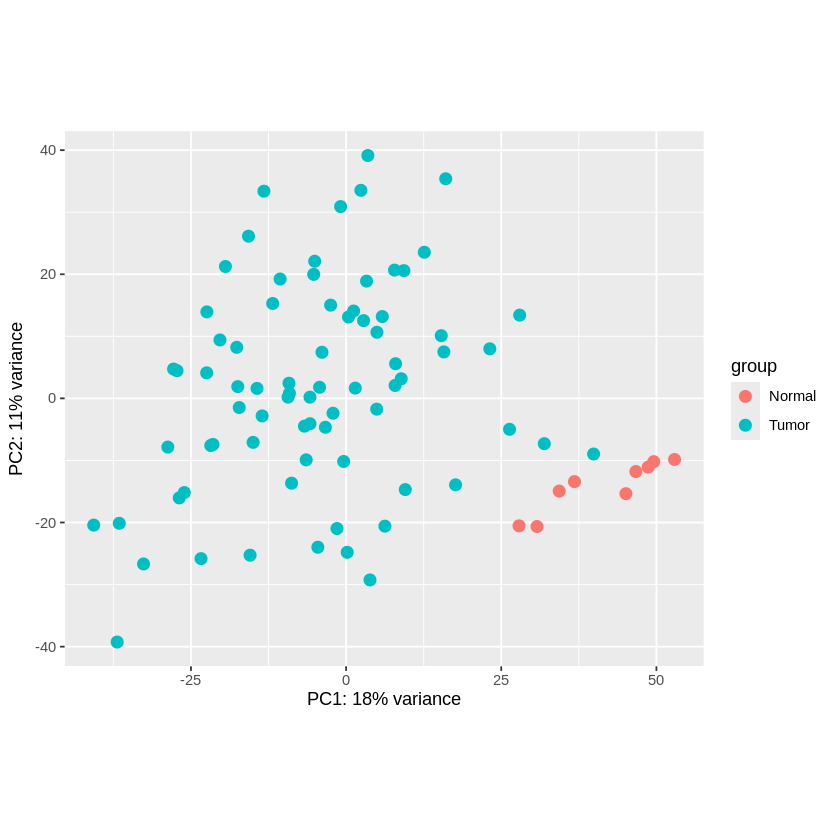

In [ ]:
# PCA 실행 - batch 교정 결과 시각화

# 1. 데이터 정규화 (vst 변환)
vsd <- vst(dds, blind=FALSE)

# 2. limma를 사용하여 정규화된 데이터에서 배치 효과 제거

# BiocManager가 설치되어 있지 않다면 먼저 설치합니다.
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

# limma 패키지를 설치합니다.
BiocManager::install("limma")

library(limma)
assay(vsd) <- removeBatchEffect(
  assay(vsd),
  batch = vsd$batch,
  design = model.matrix(~ vsd$condition)
)

# 3. PCA 플롯 확인
plotPCA(vsd, intgroup=c("condition"))

log2 fold change (MLE): condition Tumor vs Normal 
Wald test p-value: condition Tumor vs Normal 
DataFrame with 6 rows and 6 columns
                 baseMean log2FoldChange     lfcSE      stat      pvalue
                <numeric>      <numeric> <numeric> <numeric>   <numeric>
ENSG00000147689 6586.9503        7.40486  0.528591   14.0087 1.37958e-44
ENSG00000197172  375.4793       25.67242  1.946168   13.1913 9.85207e-40
ENSG00000184571   43.2790       22.59615  1.743503   12.9602 2.05697e-38
ENSG00000046774   37.4149       22.41071  1.826398   12.2704 1.30532e-34
ENSG00000221867  431.3939       23.14357  1.945995   11.8929 1.28814e-32
ENSG00000117650  692.3296        4.40213  0.381893   11.5271 9.63049e-31
                       padj
                  <numeric>
ENSG00000147689 4.97076e-40
ENSG00000197172 1.77490e-35
ENSG00000184571 2.47049e-34
ENSG00000046774 1.17580e-30
ENSG00000221867 9.28262e-29
ENSG00000117650 5.78327e-27


out of 55193 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 8805, 16%
LFC < 0 (down)     : 3496, 6.3%
outliers [1]       : 0, 0%
low counts [2]     : 19173, 35%
(mean count < 1)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



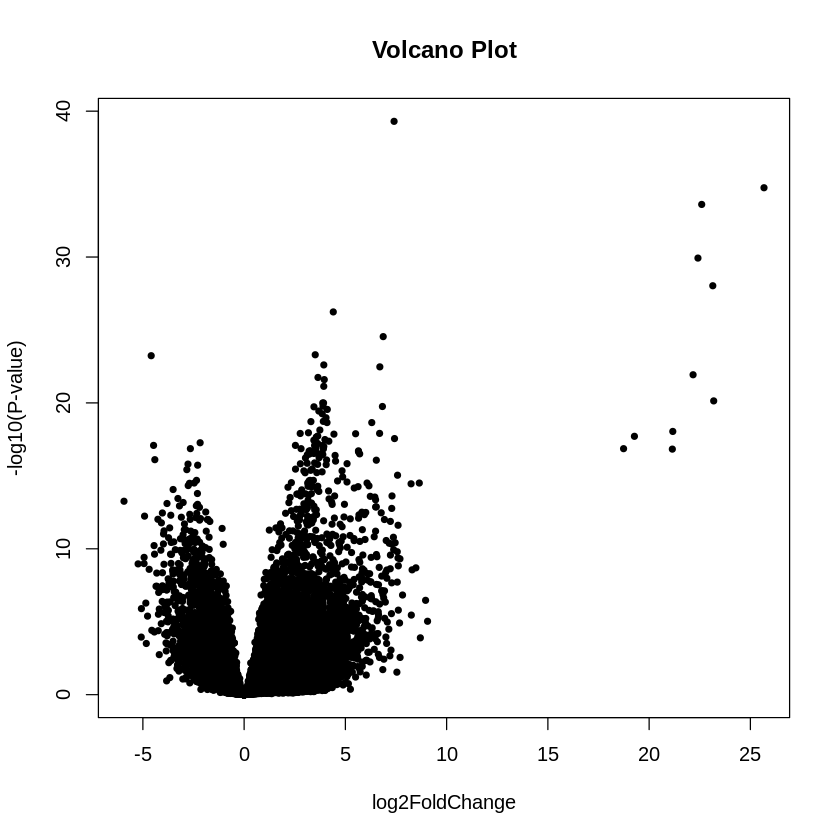

In [ ]:
# 1. 통계적으로 유의미한(padj < 0.05) 유전자만 정렬해서 보기
res_ordered <- res[order(res$padj), ]
head(res_ordered)

# 2. 요약 결과 보기 (몇 개의 유전자가 증가/감소했는지)
summary(res)

# 3. Volcano Plot 그리기 (기본형)
plot(res$log2FoldChange, -log10(res$padj),
     pch=20, main="Volcano Plot", xlab="log2FoldChange", ylab="-log10(P-value)")

In [ ]:
# 1. DESeq2 결과에서 유의미한 유전자 이름만 추출 (상위 500개 예시)
significant_genes <- row.names(res[order(res$padj), ])[1:500]

# 2. ComBat으로 보정된 데이터 불러오기
combat_data <- read.csv("ML_features_X_ComBat_R.csv", row.names = 1)

# 3. 전체 데이터에서 유의미한 유전자 열(Column)만 선택
# ※ 주의: combat_data의 컬럼명과 significant_genes의 형식이 일치해야 합니다.
final_features <- combat_data[, colnames(combat_data) %in% significant_genes]

# 4. 이제 이 final_features를 RF/XGBoost의 입력값(X)으로 사용하세요!

In [ ]:
# Load target_y data
target_y <- read.csv("ML_target_y_R.csv", row.names = 1)

# 1. Target 정보 준비 (암=1, 정상=0)
# 이미 가지고 계신 target_y 데이터 활용
target_data <- data.frame(Target = target_y$Target)
rownames(target_data) <- rownames(combat_data) # 행 이름을 샘플 ID로 일치시킴

# 2. 정예 유전자 데이터와 Target 합치기
# final_features는 위 단계에서 뽑은 [샘플 x 유의미한 유전자] 데이터프레임
final_dataset <- cbind(target_data, final_features)

# 3. CSV 파일로 저장
write.csv(final_dataset, "TCGA_Cancer_Normal_ML_Ready.csv", row.names = TRUE)

cat("✅ 머신러닝 학습을 위한 최종 데이터셋이 'TCGA_Cancer_Normal_ML_Ready.csv'로 저장되었습니다.\n")

✅ 머신러닝 학습을 위한 최종 데이터셋이 'TCGA_Lung_Cancer_ML_Ready.csv'로 저장되었습니다.
